In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, ConfusionMatrixDisplay

RANDOM_STATE = 42
df = pd.read_csv('train.csv')


In [2]:
spec_cols = [c for c in df.columns if c.startswith('X')]
na_frac = df[spec_cols].isna().mean()
usable_spec_cols = [c for c in spec_cols if na_frac[c] < 1.0]
feature_cols = usable_spec_cols + ['AEZ', 'Month']
print(f'Verwendete Features: {len(feature_cols)} (davon {len(usable_spec_cols)} Spektralbaender)')

X = df[feature_cols]
y_crop = df['Crop']
y_stage = df['Stage']


Verwendete Features: 133 (davon 131 Spektralbaender)


AEZ One hot encoden und Month Zyklisch mit sin und cos

In [4]:
from sklearn.preprocessing import OneHotEncoder

# ============================================================
# 1. AEZ: One-Hot-Encoding
# ============================================================

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

aez_encoded = encoder.fit_transform(df[['AEZ']])

aez_encoded_df = pd.DataFrame(
    aez_encoded,
    columns=encoder.get_feature_names_out(['AEZ']),
    index=df.index
)


# ============================================================
# 2. Month: zyklisches 2D-Encoding
# ============================================================

month_num = pd.to_numeric(df['Month'], errors='coerce')


# Zyklische Codierung
df_month = pd.DataFrame(index=df.index)

df_month['Month_sin'] = np.sin(
    2 * np.pi * (month_num - 1) / 12
)

df_month['Month_cos'] = np.cos(
    2 * np.pi * (month_num - 1) / 12
)


# ============================================================
# 3. Feature-Matrix zusammensetzen
# ============================================================

X = pd.concat(
    [
        df[usable_spec_cols].copy(),
        df_month,
        aez_encoded_df
    ],
    axis=1
)

print("Monats-Encoding:")
print(df_month.head())

print("\nAEZ-Features:")
print(aez_encoded_df.columns.tolist())

print(f"\nAnzahl Features insgesamt: {X.shape[1]}")

X.head()

Monats-Encoding:
      Month_sin  Month_cos
0 -5.000000e-01  -0.866025
1 -5.000000e-01  -0.866025
2 -5.000000e-01  -0.866025
3 -5.000000e-01  -0.866025
4  1.224647e-16  -1.000000

AEZ-Features:
['AEZ_2', 'AEZ_5', 'AEZ_6', 'AEZ_7', 'AEZ_8', 'AEZ_9', 'AEZ_10']

Anzahl Features insgesamt: 140


,X437,X447,X457,X468,X478,X488,X498,X508,X518,X529,...,X2345,Month_sin,Month_cos,AEZ_2,AEZ_5,AEZ_6,AEZ_7,AEZ_8,AEZ_9,AEZ_10
0,21.380647,19.123425,17.686109,17.341397,16.998645,16.676907,16.127573,15.810404,15.990405,16.141914,...,4.008810,-5.000000e-01,-0.866025,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,20.156616,18.015525,16.671422,16.203317,15.909169,15.562886,15.161740,14.845057,14.881776,14.960797,...,5.293355,-5.000000e-01,-0.866025,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,15.149693,13.715446,13.172751,12.812346,12.478285,11.997246,11.699565,11.564682,11.809068,12.255014,...,5.725971,-5.000000e-01,-0.866025,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,16.668828,14.892895,13.907130,13.593934,13.300847,12.885641,12.501532,12.368243,12.571388,12.891586,...,5.888424,-5.000000e-01,-0.866025,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,17.949177,16.185521,15.237852,15.011519,14.681677,14.329146,13.926899,13.741026,13.889799,14.019104,...,4.013303,1.224647e-16,-1.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0


durchschnittliche absorptionsrate und max absorptionsrate

In [7]:
# Originale Spektralwerte, keine Normierung
S = df[usable_spec_cols].astype(float)

# Features aus den unveränderten Werten
spectral_features = pd.DataFrame(index=df.index)

spectral_features["spectral_mean"] = S.mean(axis=1)
spectral_features["spectral_max"] = S.max(axis=1)
spectral_features["spectral_min"] = S.min(axis=1)

# Zur bestehenden Feature-Matrix hinzufügen
X = pd.concat([X, spectral_features], axis=1)

print(spectral_features.describe().round(3))

       spectral_mean  spectral_max  spectral_min
count       5591.000      5591.000      5591.000
mean          26.640        48.865         9.592
std            4.966        12.966         6.145
min           12.034        18.689         0.252
25%           23.056        39.765         3.906
50%           25.698        47.388         8.162
75%           29.908        57.058        15.590
max           50.618        93.232        27.963


Amplitude zwischen  max und min, sowie distanz dazwischen

In [8]:
import numpy as np
import pandas as pd

# ============================================================
# Spektrale Extremwerte und deren Positionen
# ============================================================

# Vollständig leere Bänder sind bereits ausgeschlossen
S = df[usable_spec_cols].astype(float)

# Positionen des Maximums und Minimums pro Zeile
# NaN-Werte werden bei argmax/argmin nicht zuverlässig ignoriert,
# deshalb verwenden wir die Pandas-Funktionen idxmax und idxmin.
max_labels = S.idxmax(axis=1)
min_labels = S.idxmin(axis=1)

# Maximale und minimale Spektralwerte
spectral_max = S.max(axis=1)
spectral_min = S.min(axis=1)

# Abstand der Extremwerte in Anzahl der Spektralbänder
band_positions = {col: i for i, col in enumerate(usable_spec_cols)}

max_positions = max_labels.map(band_positions)
min_positions = min_labels.map(band_positions)

# Features zusammenstellen
spectral_features = pd.DataFrame(index=df.index)

spectral_features["spectral_max"] = spectral_max
spectral_features["spectral_min"] = spectral_min

spectral_features["spectral_amplitude"] = (
    spectral_max - spectral_min
)

spectral_features["band_max_min_distance"] = (
    max_positions - min_positions
).abs()

# Labels der Bänder ergänzen
spectral_features["spectral_max_label"] = max_labels
spectral_features["spectral_min_label"] = min_labels

# ============================================================
# Zur bestehenden Feature-Matrix hinzufügen
# ============================================================

X = pd.concat(
    [X, spectral_features],
    axis=1
)

# ============================================================
# Kontrolle
# ============================================================

print("Neue Features:")
print(spectral_features.head())

print("\nStatistische Zusammenfassung:")
print(spectral_features[
    [
        "spectral_max",
        "spectral_min",
        "spectral_amplitude",
        "band_max_min_distance"
    ]
].describe().round(3))

print("\nFeature-Matrix:", X.shape)

Neue Features:
   spectral_max  spectral_min  spectral_amplitude  band_max_min_distance  \
0     46.250959      1.224662           45.026297                     60   
1     52.128750      4.370959           47.757791                     59   
2     60.258445      3.478598           56.779847                     60   
3     51.223910      5.841306           45.382604                     86   
4     46.628446      4.013303           42.615143                     87   

  spectral_max_label spectral_min_label  
0               X864              X2063  
1               X875              X2063  
2               X864              X2063  
3               X875              X2335  
4               X875              X2345  

Statistische Zusammenfassung:
       spectral_max  spectral_min  spectral_amplitude  band_max_min_distance
count      5591.000      5591.000            5591.000               5591.000
mean         48.865         9.592              39.273                 66.654
std          1

breite der dips und dents

In [10]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Spektraldaten vorbereiten
# ============================================================

S = df[usable_spec_cols].astype(float)

# Für diese Berechnung fehlende Werte zeilenweise interpolieren.
# Die ursprünglichen Daten in df bleiben unverändert.
S_calc = S.interpolate(axis=1, limit_direction="both")

# Falls eine Zeile vollständig fehlt, bleibt sie NaN.
# Solche Zeilen werden bei der Berechnung als fehlend behandelt.
values = S_calc.to_numpy(dtype=float)

n_samples, n_bands = values.shape

# ============================================================
# 2. Zusammenhängende Breite von Hoch- und Tiefbereich
# ============================================================

def contiguous_extreme_width(row, fraction=0.10):
    """
    fraction=0.10:
    Hochbereich: oberste 10 % der Amplitude
    Tiefbereich: unterste 10 % der Amplitude

    Gibt die Anzahl zusammenhängender Bänder zurück,
    die das globale Maximum bzw. Minimum enthalten.
    """

    valid = np.isfinite(row)

    if not valid.any():
        return np.nan, np.nan

    # Nur gültige Werte für Extremwerte verwenden
    row_min = np.nanmin(row)
    row_max = np.nanmax(row)
    amplitude = row_max - row_min

    # Bei konstanter Kurve ist keine Breite sinnvoll bestimmbar
    if amplitude == 0:
        return np.nan, np.nan

    max_idx = np.nanargmax(row)
    min_idx = np.nanargmin(row)

    high_threshold = row_max - fraction * amplitude
    low_threshold = row_min + fraction * amplitude

    # Hochbereich: vom Maximum nach links und rechts laufen
    high_left = max_idx
    while (
        high_left > 0
        and np.isfinite(row[high_left - 1])
        and row[high_left - 1] >= high_threshold
    ):
        high_left -= 1

    high_right = max_idx
    while (
        high_right < len(row) - 1
        and np.isfinite(row[high_right + 1])
        and row[high_right + 1] >= high_threshold
    ):
        high_right += 1

    high_width = high_right - high_left + 1

    # Tiefbereich: vom Minimum nach links und rechts laufen
    low_left = min_idx
    while (
        low_left > 0
        and np.isfinite(row[low_left - 1])
        and row[low_left - 1] <= low_threshold
    ):
        low_left -= 1

    low_right = min_idx
    while (
        low_right < len(row) - 1
        and np.isfinite(row[low_right + 1])
        and row[low_right + 1] <= low_threshold
    ):
        low_right += 1

    low_width = low_right - low_left + 1

    return high_width, low_width


# ============================================================
# 3. Für alle Beobachtungen berechnen
# ============================================================

widths = np.array([
    contiguous_extreme_width(row, fraction=0.10)
    for row in values
])

shape_features = pd.DataFrame(
    widths,
    columns=[
        "high_region_width",
        "low_region_width"
    ],
    index=df.index
)

# ============================================================
# 4. Zur bestehenden Feature-Matrix hinzufügen
# ============================================================

X = pd.concat([X, shape_features], axis=1)

print("Neue Features:")
print(shape_features.head())

print("\nStatistische Zusammenfassung:")
print(shape_features.describe().round(2))

Neue Features:
   high_region_width  low_region_width
0                  5                11
1                  5                 7
2                  8                29
3                  9                11
4                  4                10

Statistische Zusammenfassung:
       high_region_width  low_region_width
count            5591.00           5591.00
mean                6.54             12.70
std                 2.87              9.45
min                 1.00              1.00
25%                 5.00              5.00
50%                 5.00             11.00
75%                 8.00             19.00
max                21.00             32.00


spektralbänder buckets

In [11]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Spektralbänder vorbereiten
# ============================================================

S = df[usable_spec_cols].astype(float)

# Bandpositionen gleichmäßig über das Spektrum verteilen
# Verhindert, dass nur direkt benachbarte Bänder verglichen werden.
n_bands = len(usable_spec_cols)

positions = {
    "b10": round(0.10 * (n_bands - 1)),
    "b25": round(0.25 * (n_bands - 1)),
    "b40": round(0.40 * (n_bands - 1)),
    "b50": round(0.50 * (n_bands - 1)),
    "b60": round(0.60 * (n_bands - 1)),
    "b75": round(0.75 * (n_bands - 1)),
    "b90": round(0.90 * (n_bands - 1)),
}

bands = {
    name: S.iloc[:, idx]
    for name, idx in positions.items()
}

print("Verwendete Bandpositionen:")
for name, idx in positions.items():
    print(f"{name}: {usable_spec_cols[idx]} (Position {idx})")


# ============================================================
# 2. Verschiedene normierte Differenzindizes
# ============================================================

eps = 1e-8
index_features = pd.DataFrame(index=df.index)

# Alle Kombinationen mit ausreichend Abstand
for name_a, pos_a in positions.items():
    for name_b, pos_b in positions.items():

        if pos_b <= pos_a:
            continue

        a = bands[name_a]
        b = bands[name_b]

        # Normierte Differenz: Werte meist zwischen -1 und +1,
        # sofern die Spektralwerte nichtnegative Werte sind.
        index_features[
            f"ND_{name_a}_{name_b}"
        ] = (a - b) / (a.abs() + b.abs() + eps)

        # Einfaches Bandverhältnis
        index_features[
            f"Ratio_{name_a}_{name_b}"
        ] = a / b.where(b.abs() > eps)


# ============================================================
# 3. Zusätzliche NIR-/SWIR-ähnliche Kontraste
# ============================================================

# Vorläufige Bereiche anhand der relativen Bandpositionen.
# Diese Bezeichnungen sind KEINE bestätigten NIR-/SWIR-Bänder.

index_features["high_low_ratio"] = (
    bands["b90"] / bands["b60"].where(bands["b60"].abs() > eps)
)

index_features["high_mid_ratio"] = (
    bands["b90"] / bands["b50"].where(bands["b50"].abs() > eps)
)

index_features["high_low_ND"] = (
    (bands["b90"] - bands["b25"]) /
    (bands["b90"].abs() + bands["b25"].abs() + eps)
)

index_features["upper_spectrum_ND"] = (
    (bands["b75"] - bands["b40"]) /
    (bands["b75"].abs() + bands["b40"].abs() + eps)
)


# ============================================================
# 4. Feature-Matrix ergänzen
# ============================================================

index_features = index_features.replace([np.inf, -np.inf], np.nan)

X = pd.concat([X, index_features], axis=1)

print("\nErzeugte Index-Features:", index_features.shape[1])
print(index_features.head())

Verwendete Bandpositionen:
b10: X569 (Position 13)
b25: X763 (Position 32)
b40: X1003 (Position 52)
b50: X1205 (Position 65)
b60: X1528 (Position 78)
b75: X1730 (Position 98)
b90: X2214 (Position 117)

Erzeugte Index-Features: 46
   ND_b10_b25  Ratio_b10_b25  ND_b10_b40  Ratio_b10_b40  ND_b10_b50  \
0   -0.422361       0.406113   -0.383317       0.445800   -0.300885   
1   -0.470262       0.360301   -0.488817       0.343349   -0.439574   
2   -0.630028       0.226973   -0.575026       0.269820   -0.521306   
3   -0.556040       0.285314   -0.516630       0.318713   -0.480720   
4   -0.467127       0.363209   -0.468231       0.362183   -0.366394   

   Ratio_b10_b50  ND_b10_b60  Ratio_b10_b60  ND_b10_b75  Ratio_b10_b75  ...  \
0       0.537414    0.216440       1.552453    0.027261       1.056050  ...   
1       0.389300   -0.002719       0.994576   -0.166039       0.715209  ...   
2       0.314660    0.008082       1.016295   -0.191416       0.678675  ...   
3       0.350694   -0.03805

ndvi und andere indizes

In [12]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Wellenlängen aus Spaltennamen extrahieren
# ============================================================

# Erwartet beispielsweise Spaltennamen wie X660, X850, X1640.
wavelength_map = {}

for col in usable_spec_cols:
    try:
        wavelength_map[col] = float(col[1:])
    except ValueError:
        continue

if not wavelength_map:
    raise ValueError(
        "Keine Wellenlängen aus den Spaltennamen lesbar. "
        "Bitte die tatsächlichen Spaltennamen prüfen."
    )

available_wavelengths = np.array(list(wavelength_map.values()))

def nearest_band(target_nm):
    """Liefert das verfügbare Band, das einer Wellenlänge am nächsten liegt."""
    col = min(
        wavelength_map,
        key=lambda c: abs(wavelength_map[c] - target_nm)
    )
    return col, wavelength_map[col]


# ============================================================
# 2. Passende Bänder auswählen
# ============================================================

targets = {
    "blue": 490,
    "red": 660,
    "nir": 850,
    "nir2": 1100,
    "swir1": 1640,
    "swir2": 2200,
}

bands = {}

print("Verwendete Bänder:")
for name, target in targets.items():
    col, actual_nm = nearest_band(target)
    bands[name] = col
    print(f"{name:6s}: {col} ({actual_nm:.1f} nm; Ziel {target} nm)")


# ============================================================
# 3. Indizes berechnen
# ============================================================

S = df[usable_spec_cols].astype(float)
eps = 1e-10

def normalized_difference(a, b):
    denominator = a + b
    return (a - b) / denominator.where(denominator.abs() > eps)

index_features = pd.DataFrame(index=df.index)

blue = S[bands["blue"]]
red = S[bands["red"]]
nir = S[bands["nir"]]
nir2 = S[bands["nir2"]]
swir1 = S[bands["swir1"]]
swir2 = S[bands["swir2"]]

# NDVI: Rot und NIR
index_features["NDVI"] = normalized_difference(nir, red)

# Simple Ratio: NIR / Rot
index_features["SR_NIR_Red"] = nir / red.where(red.abs() > eps)

# NDMI / Gao-NDWI: NIR und SWIR1
index_features["NDMI_NIR_SWIR1"] = normalized_difference(nir, swir1)

# NBR: NIR und SWIR2
index_features["NBR_NIR_SWIR2"] = normalized_difference(nir, swir2)

# Alternative NIR-SWIR-Kombination
index_features["ND_NIR2_SWIR1"] = normalized_difference(nir2, swir1)

# EVI: Blue, Red und NIR
# Standardformel; nur bei geeigneten Reflexionsdaten sinnvoll.
denominator_evi = nir + 6 * red - 7.5 * blue + 1
index_features["EVI"] = (
    2.5 * (nir - red) /
    denominator_evi.where(denominator_evi.abs() > eps)
)

# Ungültige Ergebnisse markieren
index_features = index_features.replace([np.inf, -np.inf], np.nan)

# ============================================================
# 4. Zur Feature-Matrix hinzufügen
# ============================================================

X = pd.concat([X, index_features], axis=1)

print("\nErzeugte Index-Features:")
print(index_features.describe().round(3))

print("\nFeature-Matrix:", X.shape)

Verwendete Bänder:
blue  : X488 (488.0 nm; Ziel 490 nm)
red   : X661 (661.0 nm; Ziel 660 nm)
nir   : X854 (854.0 nm; Ziel 850 nm)
nir2  : X1094 (1094.0 nm; Ziel 1100 nm)
swir1 : X1639 (1639.0 nm; Ziel 1640 nm)
swir2 : X2204 (2204.0 nm; Ziel 2200 nm)

Erzeugte Index-Features:
           NDVI  SR_NIR_Red  NDMI_NIR_SWIR1  NBR_NIR_SWIR2  ND_NIR2_SWIR1  \
count  5591.000    5591.000        5591.000       5591.000       5591.000   
mean      0.485       4.232           0.178          0.406          0.124   
std       0.246       3.054           0.246          0.308          0.216   
min       0.059       1.127          -0.301         -0.207         -0.280   
25%       0.230       1.598          -0.055          0.117         -0.084   
50%       0.501       3.009           0.158          0.410          0.121   
75%       0.726       6.306           0.428          0.722          0.335   
max       0.877      15.273           0.614          0.872          0.546   

             EVI  
count   559

In [13]:
import numpy as np
import pandas as pd

# ============================================================
# 1. Spektraldaten vorbereiten
# ============================================================

S = df[usable_spec_cols].astype(float)

# Zeilenweise interpolieren, damit fehlende Werte keine
# künstlichen Sprünge in den Ableitungen verursachen.
S_calc = S.interpolate(axis=1, limit_direction="both")

# Vollständig fehlende Zeilen bleiben ungültig.
values = S_calc.to_numpy(dtype=float)

# ============================================================
# 2. Erste Differenz zwischen benachbarten Spektralbändern
# ============================================================

diff = np.diff(values, axis=1)

# Ungültige Differenzen ausschließen
diff[~np.isfinite(diff)] = np.nan

# ============================================================
# 3. Drei neue Features berechnen
# ============================================================

slope_features = pd.DataFrame(index=df.index)

# Maximale positive Änderung zwischen benachbarten Bändern
slope_features["max_positive_slope"] = np.nanmax(
    np.where(diff >= 0, diff, np.nan),
    axis=1
)

# Maximale negative Änderung zwischen benachbarten Bändern
slope_features["max_negative_slope"] = np.nanmin(
    np.where(diff <= 0, diff, np.nan),
    axis=1
)

# Gesamte absolute Variation der Spektralkurve
slope_features["total_spectral_variation"] = np.nansum(
    np.abs(diff),
    axis=1
)

# Zeilen ohne gültige Differenzen korrekt als fehlend markieren
invalid_rows = ~np.isfinite(values).any(axis=1)
slope_features.loc[invalid_rows, :] = np.nan

# ============================================================
# 4. Zur bestehenden Feature-Matrix hinzufügen
# ============================================================

X = pd.concat(
    [X, slope_features],
    axis=1
)

# ============================================================
# 5. Ergebnisse kontrollieren
# ============================================================

print("Neue Features:")
print(slope_features.head())

print("\nStatistische Zusammenfassung:")
print(slope_features.describe().round(3))

print("\nAnzahl fehlender Werte:")
print(slope_features.isna().sum())

print("\nFeature-Matrix:", X.shape)

Neue Features:
   max_positive_slope  max_negative_slope  total_spectral_variation
0            6.483575          -12.234903                165.297486
1            6.621009          -13.951665                190.034633
2           10.066265          -19.315316                201.771960
3            7.980326          -15.046919                177.739899
4            6.430469           -8.689947                186.144432

Statistische Zusammenfassung:
       max_positive_slope  max_negative_slope  total_spectral_variation
count            5591.000            5591.000                  5591.000
mean                6.728             -12.327                   171.928
std                 3.206               4.794                    49.204
min                 1.053             -31.044                    62.932
25%                 3.890             -15.642                   133.808
50%                 6.600             -12.068                   170.090
75%                 9.124              -8.

mdodel. erst random forest dann nn

Train: (3913, 212) Test: (1678, 212)

Crop - Balanced Accuracy: 0.829
Crop - Macro F1:          0.853


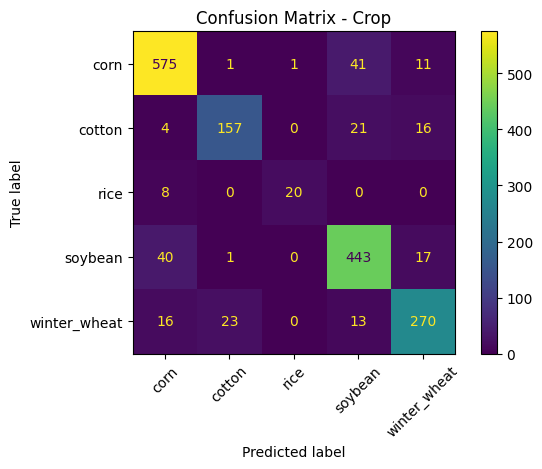


Stage - Balanced Accuracy: 0.821
Stage - Macro F1:          0.834


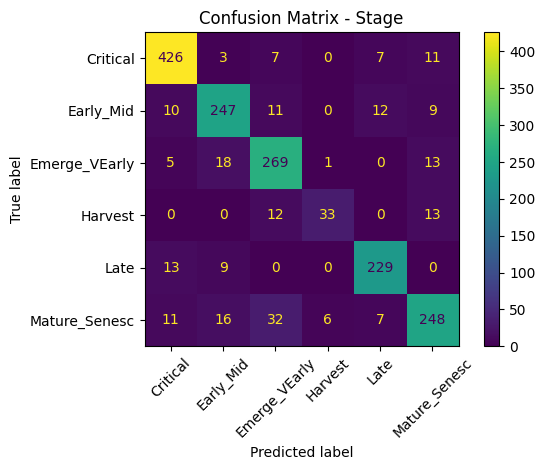

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. Modellfeatures vorbereiten
# ============================================================

# Label-Spalten der Extremwerte sind kategoriale Beschreibungen
# und werden vorerst nicht als Features verwendet.
X_model = X.drop(
    columns=["spectral_max_label", "spectral_min_label"],
    errors="ignore"
).copy()

# Sicherstellen, dass alle Modellfeatures numerisch sind
X_model = X_model.apply(pd.to_numeric, errors="coerce")

# Unendliche Werte als fehlend markieren
X_model = X_model.replace([float("inf"), -float("inf")], float("nan"))

# ============================================================
# 2. Train-Test-Split
# ============================================================

X_train, X_test, y_crop_train, y_crop_test, y_stage_train, y_stage_test = (
    train_test_split(
        X_model,
        y_crop,
        y_stage,
        test_size=0.3,
        stratify=y_crop,
        random_state=RANDOM_STATE
    )
)

print("Train:", X_train.shape, "Test:", X_test.shape)


# ============================================================
# 3. Pipeline
# ============================================================

def make_pipeline():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])


# ============================================================
# 4. Crop-Klassifikation
# ============================================================

crop_pipeline = make_pipeline()
crop_pipeline.fit(X_train, y_crop_train)

crop_pred = crop_pipeline.predict(X_test)

crop_bacc = balanced_accuracy_score(y_crop_test, crop_pred)
crop_f1 = f1_score(y_crop_test, crop_pred, average="macro")

print(f"\nCrop - Balanced Accuracy: {crop_bacc:.3f}")
print(f"Crop - Macro F1:          {crop_f1:.3f}")

ConfusionMatrixDisplay.from_predictions(
    y_crop_test,
    crop_pred,
    xticks_rotation=45
)

plt.title("Confusion Matrix - Crop")
plt.tight_layout()
plt.show()


# ============================================================
# 5. Stage-Klassifikation
# ============================================================

stage_pipeline = make_pipeline()
stage_pipeline.fit(X_train, y_stage_train)

stage_pred = stage_pipeline.predict(X_test)

stage_bacc = balanced_accuracy_score(y_stage_test, stage_pred)
stage_f1 = f1_score(y_stage_test, stage_pred, average="macro")

print(f"\nStage - Balanced Accuracy: {stage_bacc:.3f}")
print(f"Stage - Macro F1:          {stage_f1:.3f}")

ConfusionMatrixDisplay.from_predictions(
    y_stage_test,
    stage_pred,
    xticks_rotation=45
)

plt.title("Confusion Matrix - Stage")
plt.tight_layout()
plt.show()

Datensätze: 5591
Features: 208
Crop-Klassen: ['corn', 'cotton', 'rice', 'soybean', 'winter_wheat']
Stage-Klassen: ['Critical', 'Early_Mid', 'Emerge_VEarly', 'Harvest', 'Late', 'Mature_Senesc']

Trainingsdaten: (3913, 208)
Testdaten: (1678, 208)

Aufgabe: Crop
Balanced Accuracy: 0.9109
Macro-F1:          0.9078
Trainierte Iterationen: 173


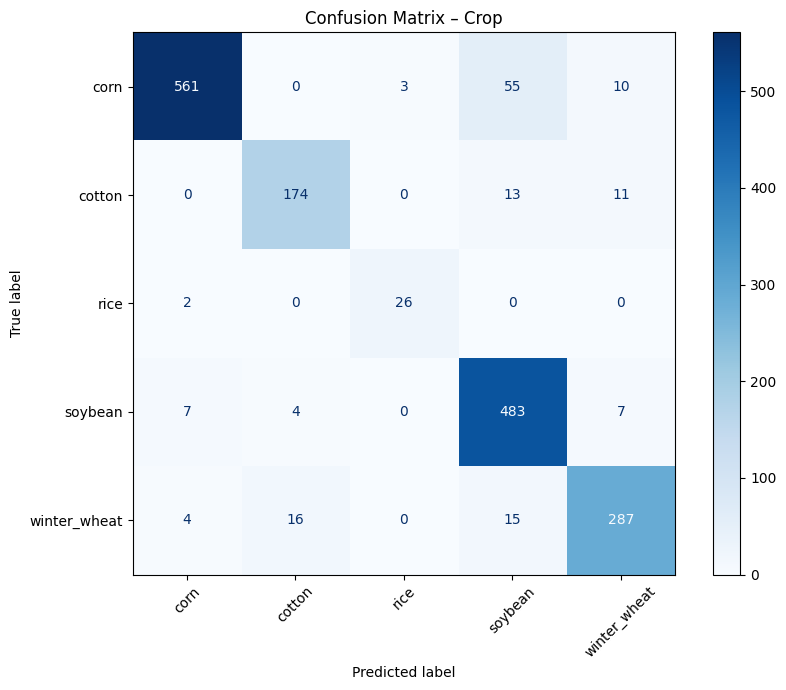


Aufgabe: Stage
Balanced Accuracy: 0.8956
Macro-F1:          0.8865
Trainierte Iterationen: 242


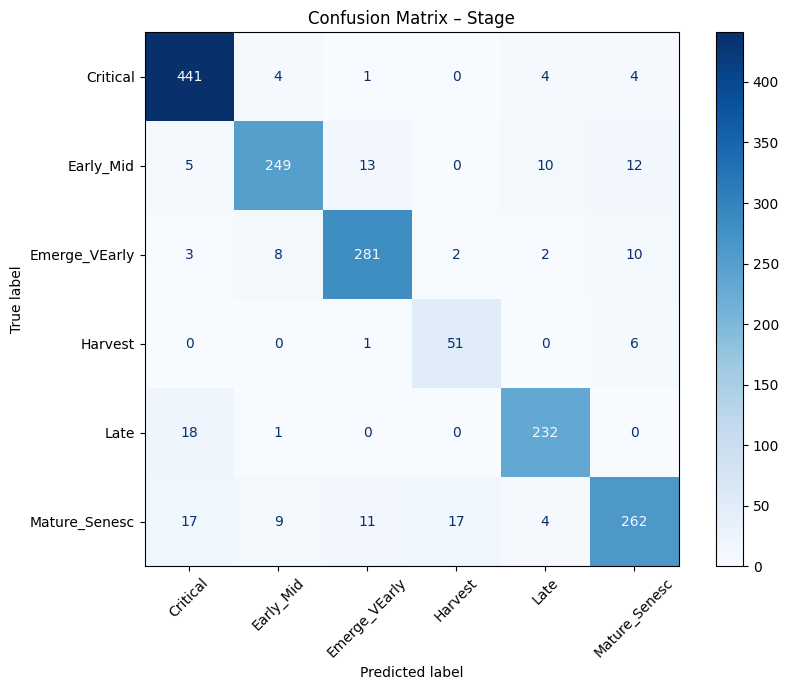


Berechne Feature Importance für Crop ...

Top 20 Features – Crop:
      Feature  Importance_Mean  Importance_Std
        AEZ_7         0.165977        0.001592
        AEZ_5         0.086563        0.002773
    Month_sin         0.085901        0.005600
         X722         0.065733        0.006319
        AEZ_8         0.047605        0.006971
         X712         0.039073        0.003387
        AEZ_9         0.036910        0.002388
       AEZ_10         0.030892        0.005750
    Month_cos         0.024696        0.003028
         X732         0.017780        0.003439
        AEZ_6         0.016461        0.005488
Ratio_b25_b40         0.015141        0.002889
         X478         0.014550        0.005448
   ND_b25_b40         0.014503        0.002644
        AEZ_2         0.014359        0.000607
         X447         0.013980        0.004586
         X457         0.012630        0.005512
        X1255         0.010625        0.002816
         X834         0.010088        0.

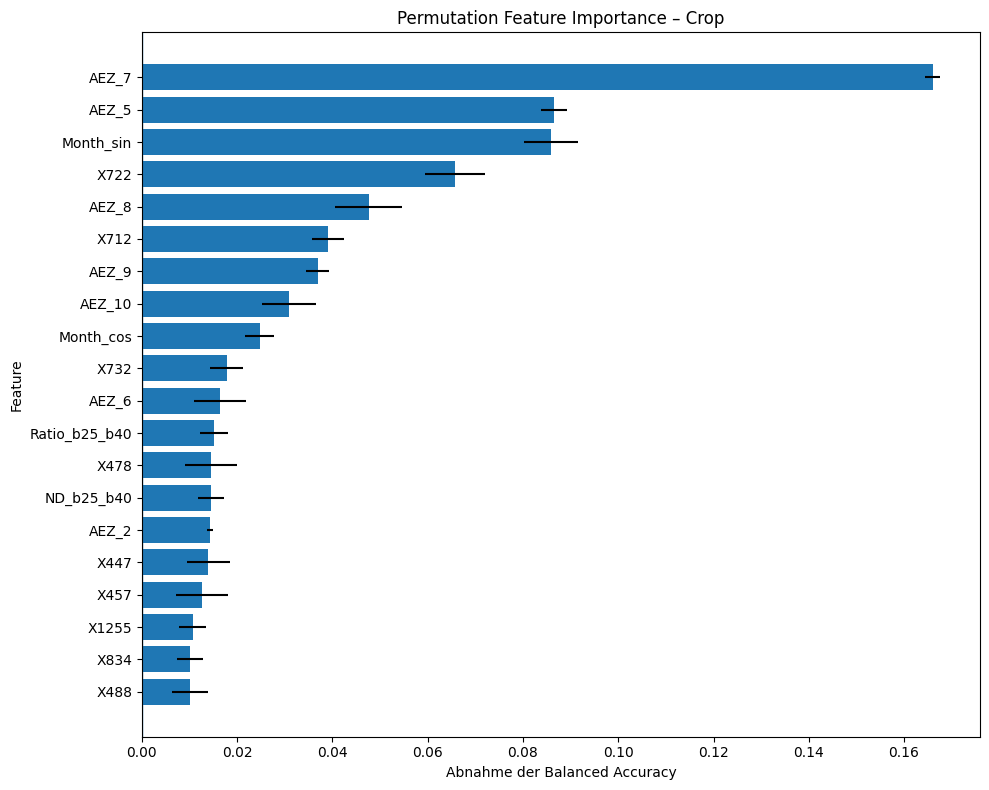


Berechne Feature Importance für Stage ...

Top 20 Features – Stage:
      Feature  Importance_Mean  Importance_Std
    Month_cos         0.202769        0.008723
    Month_sin         0.165608        0.014720
        AEZ_9         0.058069        0.007141
       AEZ_10         0.037629        0.005646
   ND_b40_b50         0.027889        0.005655
        AEZ_8         0.025909        0.002943
         X447         0.022712        0.001879
         X722         0.021068        0.005730
Ratio_b40_b50         0.019837        0.003837
Ratio_b10_b25         0.019243        0.004736
         X468         0.019235        0.003473
        AEZ_7         0.018491        0.001617
        AEZ_5         0.018445        0.003523
Ratio_b10_b40         0.018358        0.002172
   ND_b25_b40         0.018022        0.005113
        X2305         0.016842        0.002750
   ND_b25_b50         0.015451        0.004734
        X2315         0.014152        0.002148
         X457         0.014125        

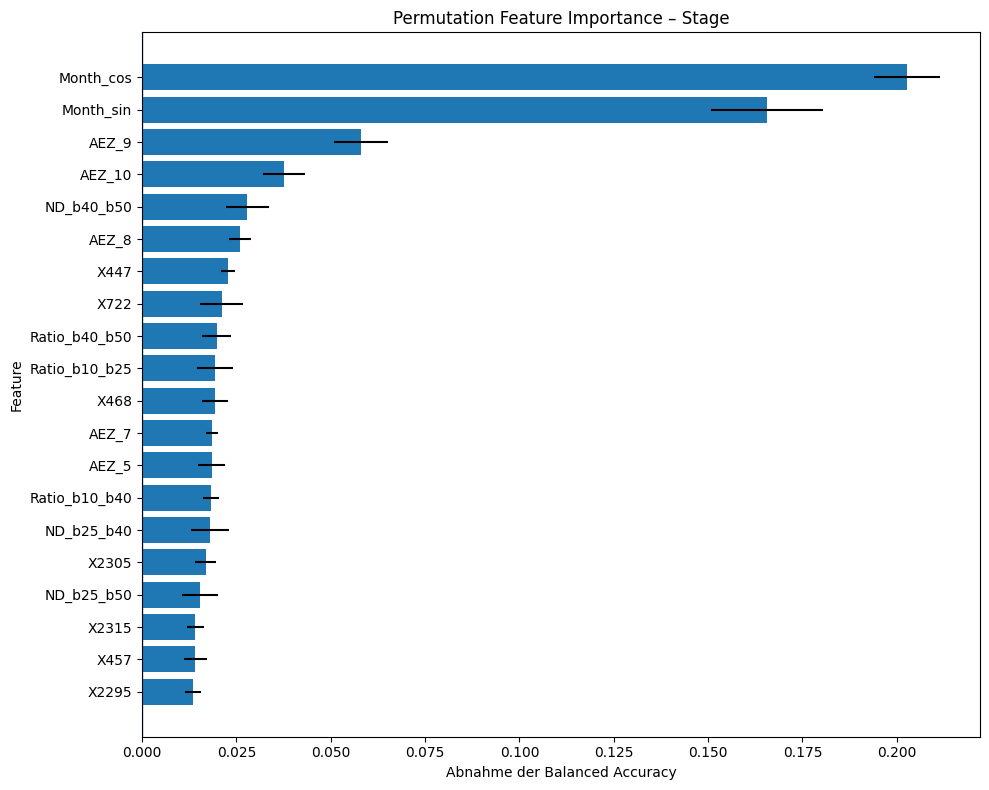


Zusammenfassung der Ergebnisse:
 Task  Balanced_Accuracy  Macro_F1
 Crop           0.910925  0.907829
Stage           0.895604  0.886525


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

# ============================================================
# 1. Einstellungen
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.30
TOP_N = 20

# ============================================================
# 2. Features vorbereiten
# ============================================================

X_model = X.drop(
    columns=["spectral_max_label", "spectral_min_label"],
    errors="ignore"
).copy()

# Doppelte Spaltennamen entfernen, falls Features mehrfach
# an X angehängt wurden
X_model = X_model.loc[:, ~X_model.columns.duplicated()]

# Alle Features numerisch konvertieren
X_model = X_model.apply(pd.to_numeric, errors="coerce")

# Inf-Werte in fehlende Werte umwandeln
X_model = X_model.replace([np.inf, -np.inf], np.nan)

# Vollständig fehlende oder konstante Features entfernen
constant_cols = X_model.columns[
    X_model.nunique(dropna=True) <= 1
]
X_model = X_model.drop(columns=constant_cols)

# Datensätze mit fehlenden Zielvariablen entfernen
valid_rows = df[["Crop", "Stage"]].notna().all(axis=1)

X_model = X_model.loc[valid_rows].reset_index(drop=True)
y_crop = df.loc[valid_rows, "Crop"].astype(str).reset_index(drop=True)
y_stage = df.loc[valid_rows, "Stage"].astype(str).reset_index(drop=True)

print("Datensätze:", len(X_model))
print("Features:", X_model.shape[1])
print("Crop-Klassen:", sorted(y_crop.unique()))
print("Stage-Klassen:", sorted(y_stage.unique()))

# ============================================================
# 3. Train-Test-Split
# ============================================================

X_train, X_test, y_crop_train, y_crop_test, y_stage_train, y_stage_test = (
    train_test_split(
        X_model,
        y_crop,
        y_stage,
        test_size=TEST_SIZE,
        stratify=y_crop,
        random_state=RANDOM_STATE
    )
)

print("\nTrainingsdaten:", X_train.shape)
print("Testdaten:", X_test.shape)

# ============================================================
# 4. Modell definieren
# ============================================================

def make_nn_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("nn", MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            alpha=0.001,
            batch_size=64,
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=False,
            n_iter_no_change=20,
            random_state=RANDOM_STATE
        ))
    ])

# ============================================================
# 5. Trainieren und evaluieren
# ============================================================

def evaluate_nn(X_train, X_test, y_train, y_test, task_name):

    model = make_nn_pipeline()

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    bacc = balanced_accuracy_score(y_test, pred)
    macro_f1 = f1_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    print("\n" + "=" * 50)
    print(f"Aufgabe: {task_name}")
    print("=" * 50)
    print(f"Balanced Accuracy: {bacc:.4f}")
    print(f"Macro-F1:          {macro_f1:.4f}")
    print(
        "Trainierte Iterationen:",
        model.named_steps["nn"].n_iter_
    )

    fig, ax = plt.subplots(figsize=(9, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        xticks_rotation=45,
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"Confusion Matrix – {task_name}")
    plt.tight_layout()
    plt.show()

    return model, pred, bacc, macro_f1


# Crop-Modell
crop_model, crop_pred, crop_bacc, crop_f1 = evaluate_nn(
    X_train,
    X_test,
    y_crop_train,
    y_crop_test,
    "Crop"
)

# Stage-Modell
stage_model, stage_pred, stage_bacc, stage_f1 = evaluate_nn(
    X_train,
    X_test,
    y_stage_train,
    y_stage_test,
    "Stage"
)

# ============================================================
# 6. Permutation Feature Importance
# ============================================================

def calculate_feature_importance(
    model,
    X_test,
    y_test,
    task_name,
    top_n=TOP_N
):
    print(f"\nBerechne Feature Importance für {task_name} ...")

    result = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="balanced_accuracy",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance_Mean": result.importances_mean,
        "Importance_Std": result.importances_std
    }).sort_values(
        "Importance_Mean",
        ascending=False
    ).reset_index(drop=True)

    print(f"\nTop {top_n} Features – {task_name}:")
    print(
        importance_df.head(top_n).to_string(index=False)
    )

    plot_df = importance_df.head(top_n).sort_values(
        "Importance_Mean",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, 8))

    ax.barh(
        plot_df["Feature"],
        plot_df["Importance_Mean"],
        xerr=plot_df["Importance_Std"]
    )

    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Abnahme der Balanced Accuracy")
    ax.set_ylabel("Feature")
    ax.set_title(f"Permutation Feature Importance – {task_name}")

    plt.tight_layout()
    plt.show()

    return importance_df


crop_importance = calculate_feature_importance(
    crop_model,
    X_test,
    y_crop_test,
    "Crop"
)

stage_importance = calculate_feature_importance(
    stage_model,
    X_test,
    y_stage_test,
    "Stage"
)

# ============================================================
# 7. Ergebnisse zusammenfassen
# ============================================================

summary = pd.DataFrame({
    "Task": ["Crop", "Stage"],
    "Balanced_Accuracy": [crop_bacc, stage_bacc],
    "Macro_F1": [crop_f1, stage_f1]
})

print("\nZusammenfassung der Ergebnisse:")
print(summary.to_string(index=False))

Datensätze: 5591
Features: 208

Anzahl gemeinsamer Klassen: 23

Häufigste gemeinsame Klassen:
corn|Critical                 675
soybean|Critical              652
winter_wheat|Emerge_VEarly    608
corn|Late                     557
soybean|Early_Mid             465
corn|Mature_Senesc            399
winter_wheat|Mature_Senesc    379
cotton|Early_Mid              253
soybean|Late                  233
corn|Early_Mid                212
cotton|Emerge_VEarly          172
cotton|Critical               158
corn|Emerge_VEarly            152
soybean|Mature_Senesc         146
soybean|Emerge_VEarly         106
Name: count, dtype: int64

Seltene gemeinsame Klassen (max. 20 Beispiele):
cotton|Harvest    11
Name: count, dtype: int64

Trainingsdaten: (3913, 208)
Testdaten: (1678, 208)

Gemeinsame Crop-Stage-Klassifikation
Anzahl Klassen:      23
Balanced Accuracy:   0.8617
Macro-F1:            0.8468
Trainierte Iterationen: 210


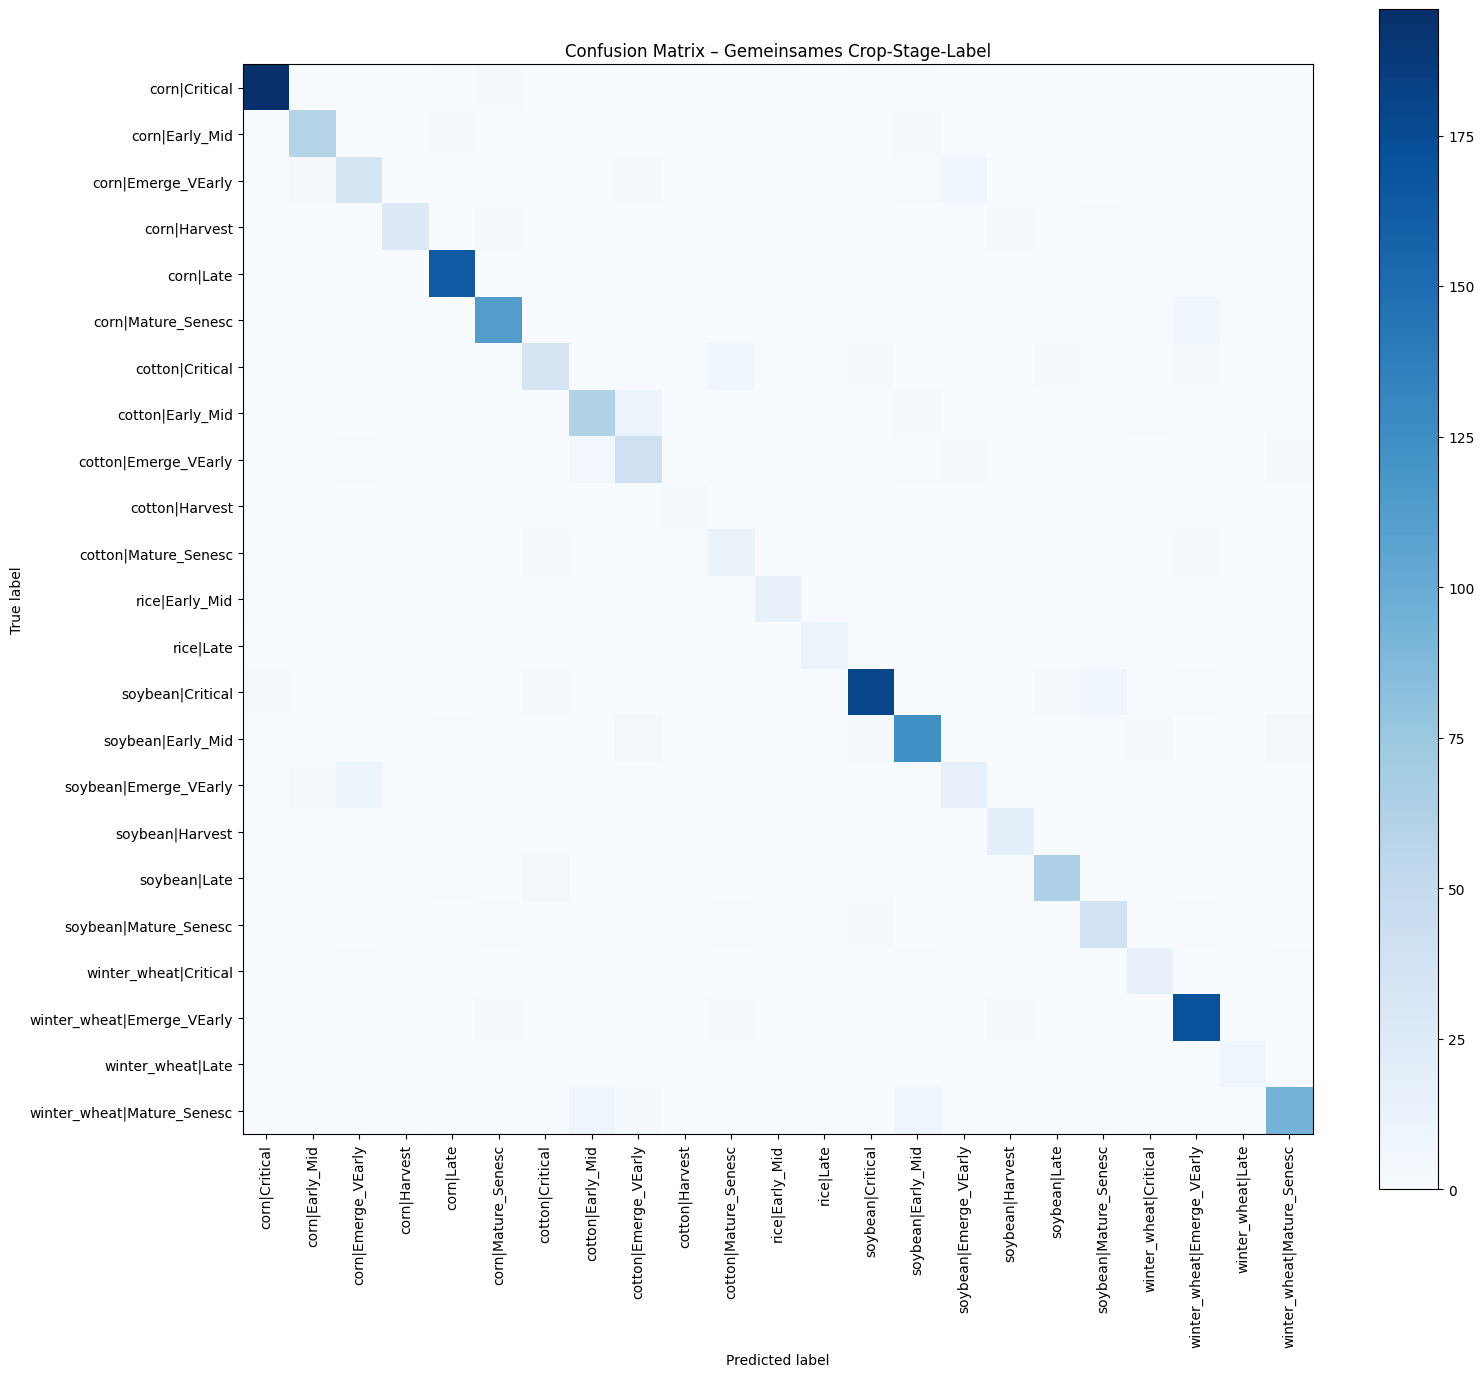


Auswertung nach Zerlegung der gemeinsamen Vorhersage

Crop:
Balanced Accuracy: 0.9270
Macro-F1:          0.9244

Stage:
Balanced Accuracy: 0.9149
Macro-F1:          0.9139


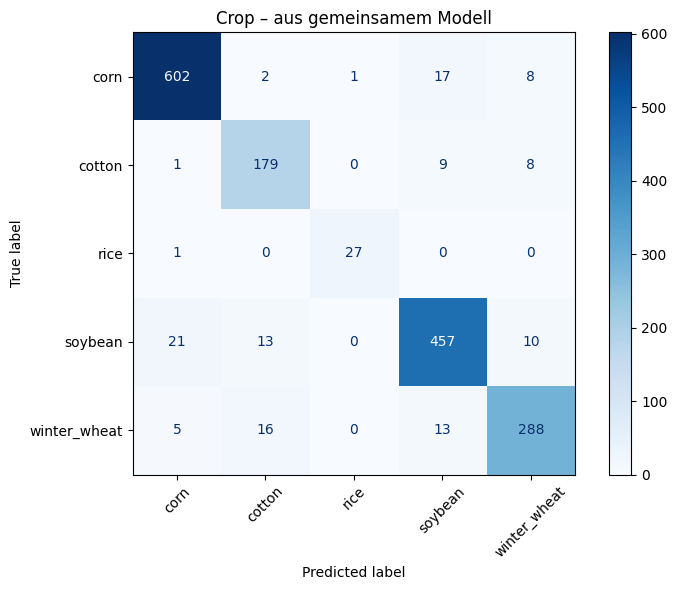

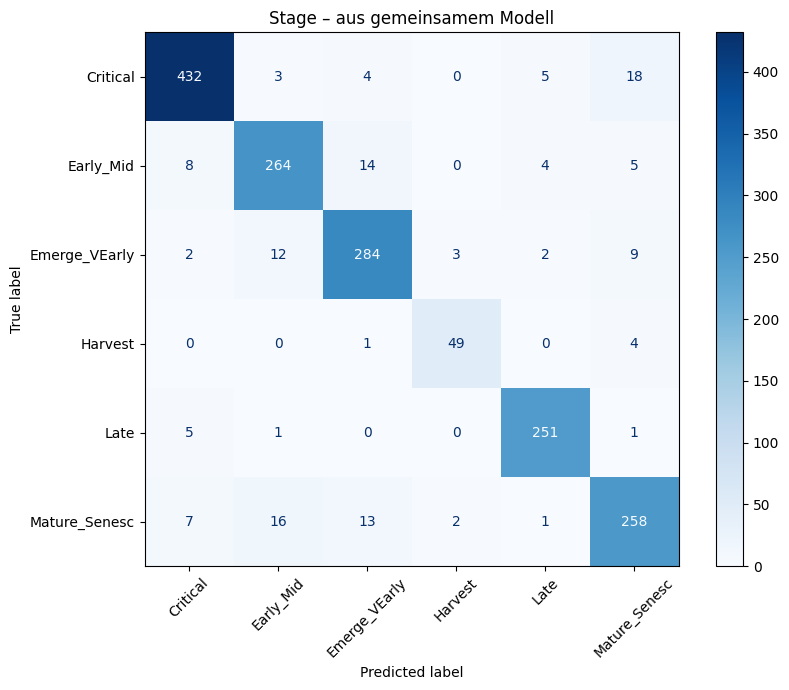


Berechne Permutation Feature Importance ...

Top 20 Features – gemeinsames Modell:
           Feature  Importance_Mean  Importance_Std
         Month_sin         0.240066        0.011694
         Month_cos         0.144978        0.013142
             AEZ_8         0.079104        0.007225
             AEZ_7         0.071309        0.002807
              X722         0.071216        0.012711
             AEZ_5         0.063700        0.006341
             AEZ_9         0.058739        0.003346
            AEZ_10         0.041065        0.005725
        ND_b25_b40         0.035973        0.008246
              X732         0.035090        0.004451
             AEZ_2         0.033786        0.001727
     Ratio_b25_b40         0.032501        0.006108
             AEZ_6         0.030060        0.006117
              X712         0.029501        0.009442
 high_region_width         0.025547        0.002683
        ND_b25_b50         0.024507        0.004365
        ND_b40_b50         0.023

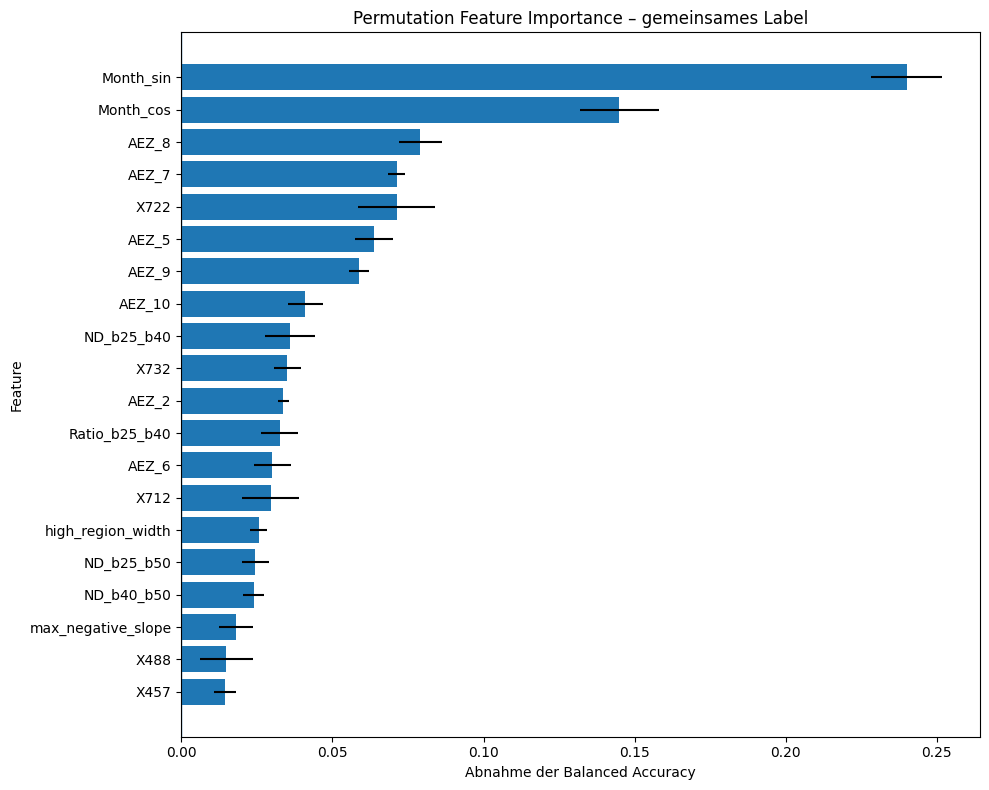


Ergebnisübersicht:
                        Task  Balanced_Accuracy  Macro_F1
Gemeinsames Crop-Stage-Label           0.861725  0.846789
 Crop aus gemeinsamem Modell           0.927011  0.924372
Stage aus gemeinsamem Modell           0.914867  0.913942


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

# ============================================================
# 1. Einstellungen
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.30
TOP_N = 20

# ============================================================
# 2. Features vorbereiten
# ============================================================

# X ist deine bereits erstellte Feature-Matrix
X_model = X.drop(
    columns=["spectral_max_label", "spectral_min_label"],
    errors="ignore"
).copy()

# Doppelte Spaltennamen entfernen
X_model = X_model.loc[:, ~X_model.columns.duplicated()]

# Alle Features numerisch konvertieren
X_model = X_model.apply(pd.to_numeric, errors="coerce")

# Unendliche Werte als fehlend behandeln
X_model = X_model.replace([np.inf, -np.inf], np.nan)

# Vollständig fehlende oder konstante Features entfernen
constant_cols = X_model.columns[
    X_model.nunique(dropna=True) <= 1
]
X_model = X_model.drop(columns=constant_cols)

# Fehlende Zielvariablen entfernen
valid_rows = df[["Crop", "Stage"]].notna().all(axis=1)

X_model = X_model.loc[valid_rows].reset_index(drop=True)
y_crop = df.loc[valid_rows, "Crop"].astype(str).reset_index(drop=True)
y_stage = df.loc[valid_rows, "Stage"].astype(str).reset_index(drop=True)

print("Datensätze:", len(X_model))
print("Features:", X_model.shape[1])

# ============================================================
# 3. Gemeinsames Label erzeugen
# ============================================================

# Beispiel: corn_Critical, soybean_Late
y_joint = y_crop + "|" + y_stage

print("\nAnzahl gemeinsamer Klassen:", y_joint.nunique())
print("\nHäufigste gemeinsame Klassen:")
print(y_joint.value_counts().head(15))

print("\nSeltene gemeinsame Klassen (max. 20 Beispiele):")
print(y_joint.value_counts()[y_joint.value_counts() <= 20])

# ============================================================
# 4. Train-Test-Split
# ============================================================

# Der gemeinsame Split wird nach dem gemeinsamen Label stratifiziert.
# Das funktioniert nur, wenn jede Klasse genügend Beispiele enthält.
class_counts = y_joint.value_counts()

if class_counts.min() < 2:
    print(
        "\nWARNUNG: Mindestens eine gemeinsame Klasse hat weniger "
        "als zwei Beispiele. Eine stratifizierte Aufteilung ist "
        "damit nicht möglich."
    )

    # Fallback: Split nach Crop, damit zumindest die Crop-Verteilung
    # möglichst gut erhalten bleibt.
    stratify_labels = y_crop
else:
    stratify_labels = y_joint

X_train, X_test, y_joint_train, y_joint_test = train_test_split(
    X_model,
    y_joint,
    test_size=TEST_SIZE,
    stratify=stratify_labels,
    random_state=RANDOM_STATE
)

print("\nTrainingsdaten:", X_train.shape)
print("Testdaten:", X_test.shape)

# ============================================================
# 5. Neuronales Netz definieren
# ============================================================

def make_nn_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("nn", MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            alpha=0.001,
            batch_size=64,
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=False,
            n_iter_no_change=20,
            random_state=RANDOM_STATE
        ))
    ])

# ============================================================
# 6. Gemeinsames Modell trainieren
# ============================================================

joint_model = make_nn_pipeline()

joint_model.fit(X_train, y_joint_train)

joint_pred = joint_model.predict(X_test)

print("\n" + "=" * 55)
print("Gemeinsame Crop-Stage-Klassifikation")
print("=" * 55)

joint_bacc = balanced_accuracy_score(
    y_joint_test,
    joint_pred
)

joint_f1 = f1_score(
    y_joint_test,
    joint_pred,
    average="macro",
    zero_division=0
)

print(f"Anzahl Klassen:      {y_joint.nunique()}")
print(f"Balanced Accuracy:   {joint_bacc:.4f}")
print(f"Macro-F1:            {joint_f1:.4f}")
print(
    "Trainierte Iterationen:",
    joint_model.named_steps["nn"].n_iter_
)

# Confusion Matrix der gemeinsamen Klassen
# Bei vielen Klassen kann diese Grafik sehr groß werden.
joint_labels = sorted(y_joint.unique())

fig, ax = plt.subplots(figsize=(16, 14))

ConfusionMatrixDisplay.from_predictions(
    y_joint_test,
    joint_pred,
    labels=joint_labels,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    include_values=False
)

ax.set_title("Confusion Matrix – Gemeinsames Crop-Stage-Label")
plt.tight_layout()
plt.show()

# ============================================================
# 7. Gemeinsame Vorhersagen wieder zerlegen
# ============================================================

# Labels wurden mit Crop + "_" + Stage erzeugt.
# Deshalb teilen wir am ersten Unterstrich.
def split_joint_labels(labels):
    parts = pd.Series(labels).str.split(
        "|",
        n=1,
        expand=True,
        regex=False
    )

    return (
        parts.iloc[:, 0].to_numpy(),
        parts.iloc[:, 1].to_numpy()
    )


# Tatsächliche gemeinsame Labels und Vorhersagen zerlegen
true_crop, true_stage = split_joint_labels(y_joint_test)
pred_crop, pred_stage = split_joint_labels(joint_pred)

# Crop-Kennzahlen
crop_bacc = balanced_accuracy_score(true_crop, pred_crop)
crop_f1 = f1_score(
    true_crop,
    pred_crop,
    average="macro",
    zero_division=0
)

# Stage-Kennzahlen
stage_bacc = balanced_accuracy_score(true_stage, pred_stage)
stage_f1 = f1_score(
    true_stage,
    pred_stage,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 55)
print("Auswertung nach Zerlegung der gemeinsamen Vorhersage")
print("=" * 55)

print("\nCrop:")
print(f"Balanced Accuracy: {crop_bacc:.4f}")
print(f"Macro-F1:          {crop_f1:.4f}")

print("\nStage:")
print(f"Balanced Accuracy: {stage_bacc:.4f}")
print(f"Macro-F1:          {stage_f1:.4f}")

# Crop-Confusion-Matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    true_crop,
    pred_crop,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title("Crop – aus gemeinsamem Modell")
plt.tight_layout()
plt.show()

# Stage-Confusion-Matrix
fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    true_stage,
    pred_stage,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title("Stage – aus gemeinsamem Modell")
plt.tight_layout()
plt.show()

# ============================================================
# 8. Permutation Feature Importance
# ============================================================

print("\nBerechne Permutation Feature Importance ...")

importance_result = permutation_importance(
    joint_model,
    X_test,
    y_joint_test,
    scoring="balanced_accuracy",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

joint_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print(f"\nTop {TOP_N} Features – gemeinsames Modell:")
print(joint_importance.head(TOP_N).to_string(index=False))

plot_df = joint_importance.head(TOP_N).sort_values(
    "Importance_Mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_Std"]
)

ax.axvline(0, linewidth=1)
ax.set_xlabel("Abnahme der Balanced Accuracy")
ax.set_ylabel("Feature")
ax.set_title("Permutation Feature Importance – gemeinsames Label")

plt.tight_layout()
plt.show()

# ============================================================
# 9. Vergleichstabelle
# ============================================================

summary = pd.DataFrame({
    "Task": [
        "Gemeinsames Crop-Stage-Label",
        "Crop aus gemeinsamem Modell",
        "Stage aus gemeinsamem Modell"
    ],
    "Balanced_Accuracy": [
        joint_bacc,
        crop_bacc,
        stage_bacc
    ],
    "Macro_F1": [
        joint_f1,
        crop_f1,
        stage_f1
    ]
})

print("\nErgebnisübersicht:")
print(summary.to_string(index=False))